In [1]:
import yaml
import warnings

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
import sys
sys.path.append('../utils')
from utils import get_nnmd, annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [2]:
gene_df = pd.read_csv('../results/merged/gene_results.csv', index_col=0)
gene_df.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc,Bagel2_filtered_Bayesfactor,Bagel2_filtered_FDR,Bagel2_Bayesfactor,Bagel2_FDR
AATBC,1.0,1.0,0.224941,0.0,0.982900,0.744970,0.853306,0.076785,0.996410,0.887360,0.974931,0.069155,-124.940,0.113,-256.648,0.133
ACKR2,NaN,NaN,NaN,NaN,0.891700,0.248520,0.364833,-0.202520,0.580970,0.264010,0.457302,-0.026468,-41.471,0.000,-84.351,0.012
ACTA2-AS1,1.0,1.0,0.181879,0.0,0.984300,0.728860,0.910502,0.088836,0.975640,0.925350,1.000000,0.067691,-131.842,0.116,-229.044,0.134
ACTB,0.0,0.0,-5.811671,0.0,0.001057,0.000005,0.000036,-3.855500,0.000979,0.000015,0.000226,-2.153600,1111.133,0.000,1219.653,0.000
ACTG1,0.0,0.0,-5.650976,0.0,0.000782,0.000005,0.000036,-2.905100,0.000233,0.000005,0.000091,-2.855300,1438.638,0.000,1527.301,0.000


# MAGeCK Vulcano

In [44]:
gene_cdf = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0,1])
gene_cdf = gene_cdf[gene_cdf.index!='NT_Control']  # remove control
final_gene_list = pd.read_excel('../resources/Selected_genes_for_follow_up.xlsx', sheet_name=0, index_col=0)
final_gene_list['Function'].replace({'Other ': 'Other'}, inplace=True)  # fix typo
gene_cdf['is_final'] = gene_cdf.index.isin(final_gene_list.index)
gene_cdf['essentiality'] = annotate_essentiality(gene_cdf.index)
gene_cdf['Functional_category'] = None
gene_cdf.loc[final_gene_list.iloc[:-3].index, 'Functional_category'] = final_gene_list.iloc[:-3]['Function']

In [49]:
gene_cdf.Functional_category.unique()
gene_cdf.Functional_category = gene_cdf.Functional_category.replace({
    'NEG': 'Non-essential',
    'CEG': 'Essential',
})

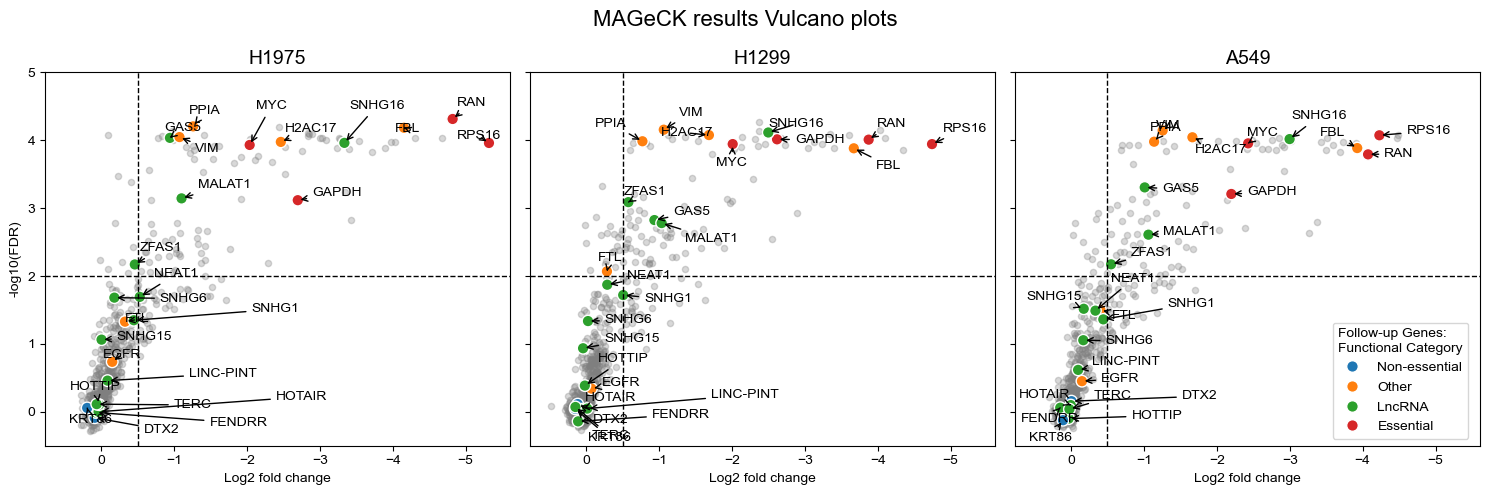

In [ ]:
# Vulcano plot
fig, axs = pl.subplots(1, 3, figsize=(5*3, 5), sharey=True, sharex=True)
for cell_line, ax in zip(cell_line_dict.values(), axs):
    gene_cdf[(cell_line, 'is_hit')] = (gene_cdf[(cell_line, f'MAGeCK_fdr')] < 0.01) & (gene_cdf[cell_line, f'MAGeCK_lfc'] < -0.5)
    gene_cdf[(cell_line, 'score')] = -np.log10(gene_cdf.loc[:, (cell_line, f'MAGeCK_fdr')])

    y = gene_cdf[(cell_line, 'score')] + np.random.normal(0, 0.1, len(gene_cdf))
    x = gene_cdf[(cell_line, f'MAGeCK_lfc')]

    ax.scatter(x[~gene_cdf.is_final], y[~gene_cdf.is_final], color='tab:grey', s=20, 
               zorder=1, alpha=0.3, label='Other Genes', marker='o')
    sns.scatterplot(x=x[gene_cdf.is_final], y=y[gene_cdf.is_final], hue=gene_cdf.loc[gene_cdf.is_final, 'Functional_category'],
                    palette='tab10', s=70, zorder=2, alpha=1, ax=ax, legend=True, marker="o", linewidth=1, edgecolor='white')
    ax.set_ylabel('-log10(FDR)')
    ax.set_xlabel('Log2 fold change')
    ax.set_title(f'{cell_line}', fontsize=14)
    if ax == axs[-1]:
        # change legend title
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles=handles[1:], labels=labels[1:], title='Follow-up Genes:\nFunctional Category', fontsize=10, loc='lower right', bbox_to_anchor=(0.99, 0))
    else:
        ax.get_legend().remove()
    ax.xaxis.set_inverted(True)
    
    ax.axhline(-np.log10(0.01), color='black', linestyle='--', lw=1)
    ax.axvline(-0.5, color='black', linestyle='--', lw=1)
    ax.set_ylim(-0.5, 5)
    
    from adjustText import adjust_text
    highlight_genes = gene_cdf.index[gene_cdf['is_final']]
    texts = []
    for gene in highlight_genes:
        txt = ax.annotate(gene, xy=(x.loc[gene], y.loc[gene]), 
                    xytext=(gene_cdf.loc[gene, (cell_line, f'MAGeCK_lfc')], gene_cdf.loc[gene, (cell_line, 'score')]),
                    arrowprops=dict(arrowstyle='->', lw=1))
        texts.append(txt)
    adjust_text(texts, ax=ax, expand=(1.4, 1.4))
pl.suptitle('MAGeCK results Vulcano plots', fontsize=16)
pl.tight_layout()
pl.savefig('../results/figures/MAGECK_vulcano_plots.pdf', bbox_inches='tight')
gene_cdf.to_csv("../results/source_tables/Fig1f_source_data.csv")
pl.show()

# Comparisons Bayes Factor from Bagel, gscreend, MAGECK

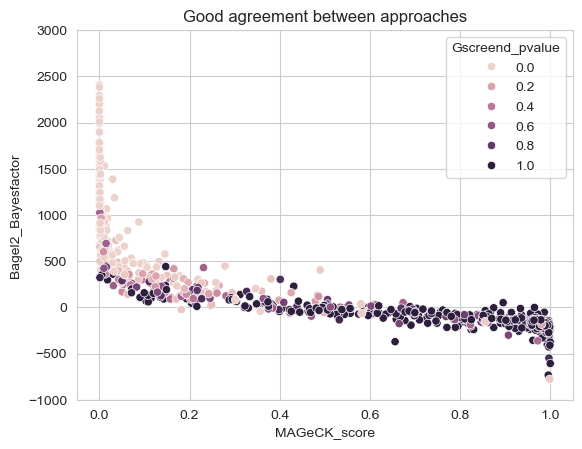

In [ ]:
# Correlate MAGeCK and BAGEL2
with sns.axes_style('whitegrid'):
    sns.scatterplot(data=gene_df, x='MAGeCK_score', y='Bagel2_Bayesfactor', hue='Gscreend_pvalue')
pl.title('Good agreement between approaches')
pl.ylim(-1000, 3000)
pl.show()

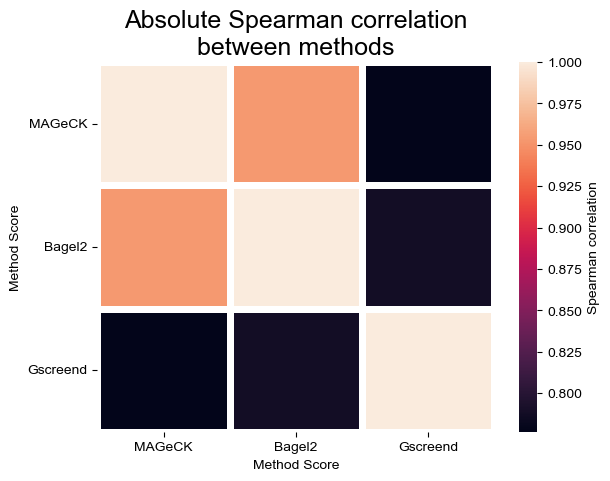

In [4]:
# Correlate all methods used
spearman = gene_df[['MAGeCK_score', 'Bagel2_Bayesfactor', 'Gscreend_pvalue']].corr(method='spearman').abs()
sns.heatmap(spearman, annot=False, linewidths=5, linecolor='white', cbar_kws={'label': 'Spearman correlation'})
pl.title('Absolute Spearman correlation\nbetween methods', fontsize=18)
pl.xlabel('Method Score')
pl.ylabel('Method Score')
pl.xticks(ticks=[0.5, 1.5, 2.5], labels=['MAGeCK', 'Bagel2', 'Gscreend'])
pl.yticks(ticks=[0.5, 1.5, 2.5], labels=['MAGeCK', 'Bagel2', 'Gscreend'], rotation=0)
pl.savefig('../results/stat_methods_evaluation/merged_methods_comparison_spearman.pdf', bbox_inches='tight')
pl.show()

# Evaluation with known essentiality from CRISPR-Cas9 screens

In [7]:
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.cm import get_cmap

In [9]:
# add essential annotation
gene_df['essentiality'] = annotate_essentiality(gene_df.index)
gene_df.essentiality.value_counts()

essentiality
unknown          504
essential        199
non-essential     31
Name: count, dtype: int64

In [10]:
gene_df.head()

,Gscreend_FDR,Gscreend_pvalue,Gscreend_LFC,Gscreend_cell_line_specificity,MAGeCK_filtered_score,MAGeCK_filtered_p-value,MAGeCK_filtered_fdr,MAGeCK_filtered_lfc,MAGeCK_score,MAGeCK_p-value,MAGeCK_fdr,MAGeCK_lfc,Bagel2_filtered_Bayesfactor,Bagel2_filtered_FDR,Bagel2_Bayesfactor,Bagel2_FDR,essentiality
AATBC,1.0,1.0,0.224941,0.0,0.982900,0.744970,0.853306,0.076785,0.996410,0.887360,0.974931,0.069155,-124.940,0.113,-256.648,0.133,unknown
ACKR2,NaN,NaN,NaN,NaN,0.891700,0.248520,0.364833,-0.202520,0.580970,0.264010,0.457302,-0.026468,-41.471,0.000,-84.351,0.012,unknown
ACTA2-AS1,1.0,1.0,0.181879,0.0,0.984300,0.728860,0.910502,0.088836,0.975640,0.925350,1.000000,0.067691,-131.842,0.116,-229.044,0.134,unknown
ACTB,0.0,0.0,-5.811671,0.0,0.001057,0.000005,0.000036,-3.855500,0.000979,0.000015,0.000226,-2.153600,1111.133,0.000,1219.653,0.000,essential
ACTG1,0.0,0.0,-5.650976,0.0,0.000782,0.000005,0.000036,-2.905100,0.000233,0.000005,0.000091,-2.855300,1438.638,0.000,1527.301,0.000,unknown


In [11]:
def plot_roc(df, key, flip_sign=False, ax=None):
    ax = pl.subplots(figsize=(4,4))[1] if ax is None else ax

    mask = (df.essentiality!='unknown') & ~df[key].isna()
    fpr, tpr, thresholds = roc_curve(df[mask].essentiality=='essential', (1-2*int(flip_sign)) * df[mask][key])

    ax.plot(fpr, tpr, linewidth=2, label=key)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'{key} ROC Curve\n(n={mask.sum()} genes)')
    

In [12]:
scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']
scores_filtered = ['MAGeCK_filtered_score', 'Bagel2_filtered_Bayesfactor']

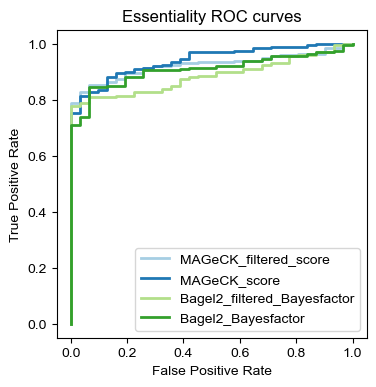

In [13]:
ax = pl.subplots(figsize=(4,4))[1]
import matplotlib.cm as cm
ax.set_prop_cycle('color', cm.get_cmap('Paired')(np.arange(0,4)))
for score, flip in zip(scores, [True, True, False, False]):
    plot_roc(gene_df, score, flip_sign=flip, ax=ax)
ax.legend()
ax.set_title('Essentiality ROC curves')
pl.savefig(f'../results/stat_methods_evaluation/joint_ROC_curves.pdf', bbox_inches='tight', dpi=300)
pl.show()

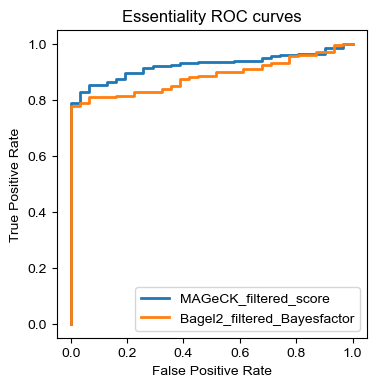

In [14]:
ax = pl.subplots(figsize=(4,4))[1]
import matplotlib.cm as cm
for score in scores_filtered:
    flip = 'MAGeCK' in score
    plot_roc(gene_df, score, flip_sign=flip, ax=ax)
ax.legend()
ax.set_title('Essentiality ROC curves')
pl.savefig(f'../results/stat_methods_evaluation/joint_ROC_curves_filtered.pdf', bbox_inches='tight', dpi=300)
pl.show()

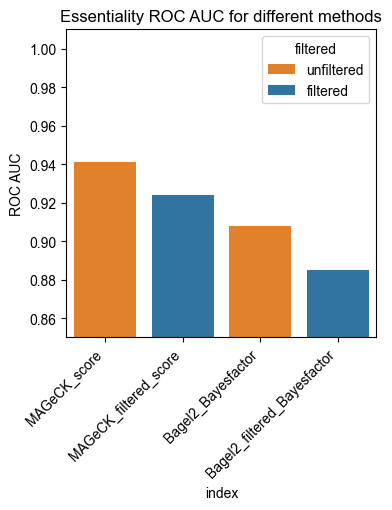

In [13]:
# ROC AUC scores
def get_auc(df, key, flip_sign=False):
    mask = (df.essentiality!='unknown') & ~df[key].isna()
    auc = roc_auc_score(df[mask].essentiality=='essential', (1-2*int(flip_sign)) * df[mask][key])
    if auc < 0.5:
        auc = 1-auc # flipped signs
    return auc

scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']
score_df = pd.Series({score: get_auc(gene_df, score) for score in scores}).to_frame()
score_df['filtered'] = ['filtered' if 'filtered' in x else 'unfiltered' for x in score_df.index]
score_df = score_df.sort_values(0, ascending=False)

fig, ax = pl.subplots(figsize=(4,4))
sns.barplot(data=score_df.reset_index(), x='index', y=0, hue='filtered', dodge=False, palette={'filtered': 'tab:blue', 'unfiltered': 'tab:orange'})
pl.xticks(rotation=45, ha='right')
pl.ylabel('ROC AUC')
pl.title('Essentiality ROC AUC for different methods')
pl.ylim(0.85, 1.01)
pl.savefig(f'../results/stat_methods_evaluation/ROC_AUC_scores_barplot.pdf', bbox_inches='tight', dpi=300)
pl.show()

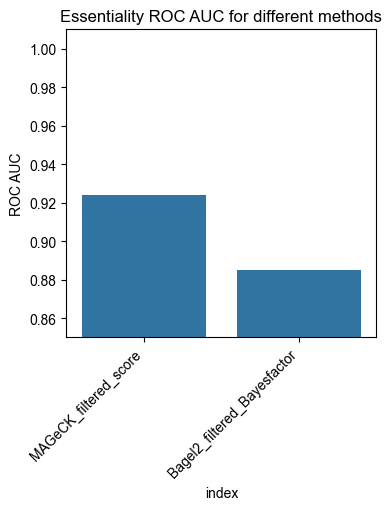

In [14]:
# ROC AUC scores
def get_auc(df, key, flip_sign=False):
    mask = (df.essentiality!='unknown') & ~df[key].isna()
    auc = roc_auc_score(df[mask].essentiality=='essential', (1-2*int(flip_sign)) * df[mask][key])
    if auc < 0.5:
        auc = 1-auc # flipped signs
    return auc

score_df = pd.Series({score: get_auc(gene_df, score) for score in scores_filtered}).to_frame()
score_df['filtered'] = ['filtered' if 'filtered' in x else 'unfiltered' for x in score_df.index]
score_df = score_df.sort_values(0, ascending=False)

fig, ax = pl.subplots(figsize=(4,4))
sns.barplot(data=score_df.reset_index(), x='index', y=0, dodge=False)
pl.xticks(rotation=45, ha='right')
pl.ylabel('ROC AUC')
pl.title('Essentiality ROC AUC for different methods')
pl.ylim(0.85, 1.01)
pl.savefig(f'../results/stat_methods_evaluation/ROC_AUC_scores_barplot_filtered.pdf', bbox_inches='tight', dpi=300)
pl.show()

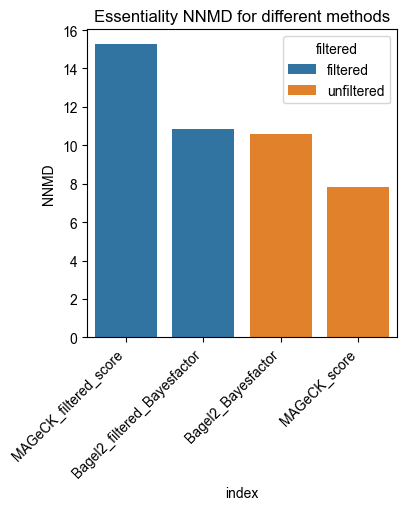

In [15]:
# NNMD
scores = ['MAGeCK_filtered_score', 'MAGeCK_score', 'Bagel2_filtered_Bayesfactor', 'Bagel2_Bayesfactor']
score_df = pd.Series({score: get_nnmd(gene_df, score) for score in scores}).to_frame()
score_df['filtered'] = ['filtered' if 'filtered' in x else 'unfiltered' for x in score_df.index]
score_df = score_df.sort_values(0, ascending=False)

fig, ax = pl.subplots(figsize=(4,4))
sns.barplot(data=score_df.reset_index(), x='index', y=0, hue='filtered', dodge=False, palette={'filtered': 'tab:blue', 'unfiltered': 'tab:orange'})
pl.xticks(rotation=45, ha='right')
pl.ylabel('NNMD')
pl.title('Essentiality NNMD for different methods')
pl.savefig(f'../results/stat_methods_evaluation/NNMD_scores_barplot.pdf', bbox_inches='tight', dpi=300)
pl.show()